# Setup

In [ ]:
!pip install --upgrade botorch

In [304]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from botorch.models import SingleTaskGP
from botorch.acquisition import LogExpectedImprovement, UpperConfidenceBound, qLogExpectedImprovement
from botorch.optim import optimize_acqf
from botorch.fit import fit_gpytorch_mll   # marginal log likelihood
from gpytorch.mlls import ExactMarginalLogLikelihood
from scipy.stats.qmc import LatinHypercube
from gpytorch.kernels import ScaleKernel, RBFKernel

# Sequential BO

In [296]:
def RGB_to_CMYK(rgb):
    R, G, B = rgb
    K = min(1 - R, 1 - G, 1 - B)
    C = (1 - R - K) / (1 - K) if (1 - K) > 0 else 0
    M = (1 - G - K) / (1 - K) if (1 - K) > 0 else 0
    Y = (1 - B - K) / (1 - K) if (1 - K) > 0 else 0
    return np.array([C, M, Y, K])

def generate_lhs_samples(n_samples=1, n_features=4):
    sampler = LatinHypercube(d=n_features)
    samples = sampler.random(n_samples)  # Generates values in [0, 1]
    return torch.tensor(samples, dtype=torch.double)

# setup
target_rgb = np.array([75, 46, 131]) / 255.0
target_cmyk = RGB_to_CMYK(target_rgb)

# latin hypercube sampling
train_x = generate_lhs_samples(n_samples=5)  # Sample 1 initial color
# computes negative Euclidean distance
train_y = -torch.norm(train_x - torch.tensor(target_cmyk, dtype=torch.double), dim=1).unsqueeze(-1)

bounds = torch.stack([torch.zeros(4), torch.ones(4)])  # defines search space (between [0,1])
n_iter = 10

for _ in range(n_iter):
    
    # 1.build and fit GP model
    # kernels: correlation between data points
    gp = SingleTaskGP(train_x, train_y, covar_module=ScaleKernel(RBFKernel()))    # retrained each step
    mll = ExactMarginalLogLikelihood(gp.likelihood, gp)
    fit_gpytorch_mll(mll)  # via MLL

    # 2.acquisition function (expected improvement)
    #EI = LogExpectedImprovement(gp, best_f=train_y.min().item())
    EI = UpperConfidenceBound(gp, beta=0.1)

    # 3.optimize acquisition to get new candidate
    candidates, _ = optimize_acqf(
        acq_function=EI,
        bounds=bounds,
        q=1,   # sequential
        num_restarts=20,   # number of optimization runs from different starting point (helps avoid local minima)
        raw_samples=256,    # number of random initial points (more samples improve exploration)
    )

    # 4.evaluate objective (distance) at new point
    new_x = candidates.detach()
    new_y = -torch.norm(new_x - torch.tensor(target_cmyk, dtype=torch.double), dim=1).unsqueeze(-1)

    # 5.update training data (one new CMYK color at each iteration)
    train_x = torch.cat([train_x, new_x])
    train_y = torch.cat([train_y, new_y])

best_idx = torch.argmax(train_y, dim=0).item()
best_distance = -train_y[best_idx].item()
best_cmyk = train_x[best_idx].numpy()
best_iteration = best_idx + 1

print(f"Best distance: {best_distance} at iteration {best_iteration}")
print("Optimal CMYK:", best_cmyk)

for i in range(len(train_y)):
    print(f"Iteration {i+1}: Distance = {-train_y[i].item()}, CMYK = {train_x[i].numpy()}")

Best distance: 0.03210037697623365 at iteration 9
Optimal CMYK: [0.41983169 0.61796713 0.         0.48204777]
Iteration 1: Distance = 0.9259282398584532, CMYK = [0.54600433 0.76197943 0.87701773 0.2386093 ]
Iteration 2: Distance = 0.4812468824938002, CMYK = [0.10254552 0.96713901 0.11524218 0.59318597]
Iteration 3: Distance = 0.5554409451095682, CMYK = [0.62289644 0.47712386 0.30413802 0.87141852]
Iteration 4: Distance = 1.0551301099641228, CMYK = [0.2033191  0.16791351 0.78962915 0.0299499 ]
Iteration 5: Distance = 0.7616719076295603, CMYK = [0.83282045 0.36126182 0.49016395 0.79102596]
Iteration 6: Distance = 0.5472551007855913, CMYK = [0.30560532 0.7928015  0.         1.        ]
Iteration 7: Distance = 0.28187643949341745, CMYK = [0.31626999 0.74913561 0.13124235 0.68578815]
Iteration 8: Distance = 0.18239374769414085, CMYK = [0.36409622 0.68847376 0.11081286 0.61037415]
Iteration 9: Distance = 0.03210037697623365, CMYK = [0.41983169 0.61796713 0.         0.48204777]
Iteration 10: 

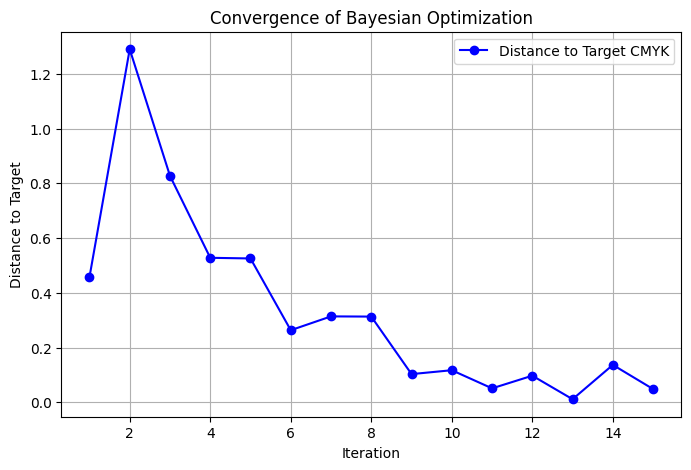

In [291]:
def plot_convergence(train_y):
    """
    Plots the Euclidean distance to the target color over iterations.
    """
    iterations = np.arange(1, len(train_y) + 1)
    distances = -train_y.numpy().flatten()  # Convert to positive distances

    plt.figure(figsize=(8, 5))
    plt.plot(iterations, distances, marker="o", linestyle="-", color="b", label="Distance to Target CMYK")
    plt.xlabel("Iteration")
    plt.ylabel("Distance to Target")
    plt.title("Convergence of Bayesian Optimization")
    plt.grid(True)
    plt.legend()
    plt.show()

# Call the convergence plot function after BO
plot_convergence(train_y)

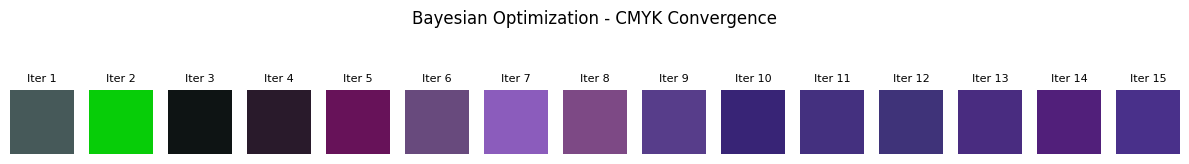

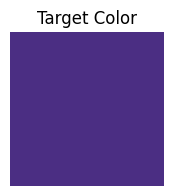

In [292]:
def CMYK_to_RGB(cmyk):
    """Convert CMYK to RGB using the standard formula."""
    C, M, Y, K = cmyk
    R = (1 - C) * (1 - K)
    G = (1 - M) * (1 - K)
    B = (1 - Y) * (1 - K)
    return np.array([R, G, B])

def visualize_iterations(train_x, target_rgb):
    """
    Visualizes the colors chosen at each iteration.
    Displays them in a sequential order.
    """
    num_samples = train_x.shape[0]
    
    # Convert CMYK to RGB for visualization
    rgb_colors = np.array([CMYK_to_RGB(cmyk) for cmyk in train_x.numpy()])
    
    # Plot the colors selected over iterations
    plt.figure(figsize=(12, 2))
    for i in range(num_samples):
        plt.subplot(1, num_samples, i + 1)
        plt.imshow([[rgb_colors[i]]], extent=[0, 1, 0, 1])
        plt.axis("off")
        plt.title(f"Iter {i+1}", fontsize=8)
    
    plt.suptitle("Bayesian Optimization - CMYK Convergence", fontsize=12)
    plt.tight_layout()
    
    # Show the target color for reference
    plt.figure(figsize=(2, 2))
    plt.imshow([[target_rgb]], extent=[0, 1, 0, 1])
    plt.axis("off")
    plt.title("Target Color", fontsize=12)
    plt.show()

# Call the visualization function after running BO
visualize_iterations(train_x, target_rgb)

# Batch BO

In [324]:
def RGB_to_CMYK(rgb):
    R, G, B = rgb
    K = min(1 - R, 1 - G, 1 - B)
    C = (1 - R - K) / (1 - K) if (1 - K) > 0 else 0
    M = (1 - G - K) / (1 - K) if (1 - K) > 0 else 0
    Y = (1 - B - K) / (1 - K) if (1 - K) > 0 else 0
    return np.array([C, M, Y, K])

def generate_lhs_samples(n_samples=1, n_features=4):
    sampler = LatinHypercube(d=n_features)
    samples = sampler.random(n_samples)  # Generates values in [0, 1]
    return torch.tensor(samples, dtype=torch.double)

# setup
target_rgb = np.array([75, 46, 131]) / 255.0
target_cmyk = RGB_to_CMYK(target_rgb)

# latin hypercube sampling
train_x = generate_lhs_samples(n_samples=2)  # sample initial color

# computes negative Euclidean distance
train_y = -torch.norm(train_x - torch.tensor(target_cmyk, dtype=torch.double), dim=1).unsqueeze(-1)

bounds = torch.stack([torch.zeros(4), torch.ones(4)])  # defines search space (between [0,1])
n_iter = 10

for _ in range(n_iter):
    
    # 1.build and fit GP model
    # kernels: correlation between data points
    gp = SingleTaskGP(train_x, train_y, covar_module=ScaleKernel(RBFKernel()))    # retrained each step
    mll = ExactMarginalLogLikelihood(gp.likelihood, gp)
    fit_gpytorch_mll(mll)  # via MLL

    # 2.acquisition function (expected improvement)
    #EI = LogExpectedImprovement(gp, best_f=train_y.min().item())
    #EI = UpperConfidenceBound(gp, beta=0.1)
    qEI = qLogExpectedImprovement(
    model=gp,
    best_f=train_y.min().item(),
    sampler=None,  # or an MC sampler for noisy objectives
)

    # 3.optimize acquisition to get new candidate
    candidates, _ = optimize_acqf(
        acq_function=qEI,
        bounds=bounds,
        q=2,   # sequential
        num_restarts=20,   # number of optimization runs from different starting point (helps avoid local minima)
        raw_samples=256,    # number of random initial points (more samples improve exploration)
    )

    # 4.evaluate objective (distance) at new point
    new_x = candidates.detach().reshape(-1, 4)
    new_y = -torch.norm(new_x - target_cmyk, dim=1).unsqueeze(-1)

    # 5.update training data (one new CMYK color at each iteration)
    train_x = torch.cat([train_x, new_x])
    train_y = torch.cat([train_y, new_y])

best_idx = torch.argmax(train_y, dim=0).item()
best_distance = -train_y[best_idx].item()
best_cmyk = train_x[best_idx].numpy()
best_iteration = best_idx + 1

print(f"Best distance: {best_distance} at iteration {best_iteration}")
print("Optimal CMYK:", best_cmyk)

for i in range(len(train_y)):
    print(f"Iteration {i+1}: Distance = {-train_y[i].item()}, CMYK = {train_x[i].numpy()}")

Best distance: 0.004128576576665111 at iteration 18
Optimal CMYK: [0.43043059 0.6512388  0.         0.48464298]
Iteration 1: Distance = 0.8436711240379051, CMYK = [0.03146448 0.86068836 0.70521773 0.59917497]
Iteration 2: Distance = 0.7427620244268429, CMYK = [0.99854162 0.32666248 0.27502893 0.27148116]
Iteration 3: Distance = 0.7784419964862601, CMYK = [0.99862534 0.3708258  0.33356559 0.18428151]
Iteration 4: Distance = 0.7236576061417836, CMYK = [0.99846351 0.2833313  0.21759585 0.35703167]
Iteration 5: Distance = 0.7880815829780978, CMYK = [0.99832124 0.18644688 0.27438787 0.40814659]
Iteration 6: Distance = 0.6654975557248177, CMYK = [0.99854022 0.34419876 0.11112016 0.37850079]
Iteration 7: Distance = 0.6022647080404995, CMYK = [1.         0.48739579 0.08055903 0.43742928]
Iteration 8: Distance = 0.663342546809743, CMYK = [0.99732667 0.36327857 0.         0.30257565]
Iteration 9: Distance = 0.38817064766989906, CMYK = [0.80523622 0.58302259 0.06004859 0.48013869]
Iteration 10: D

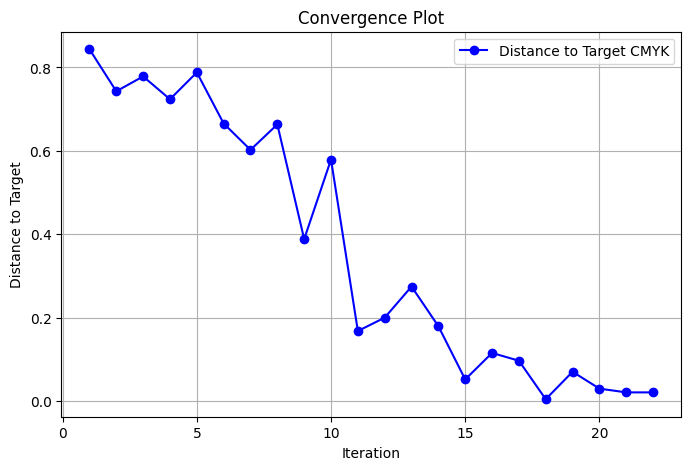

In [325]:
def plot_convergence(train_y):
    iterations = np.arange(1, len(train_y) + 1)
    distances = -train_y.numpy().flatten() 

    plt.figure(figsize=(8, 5))
    plt.plot(iterations, distances, marker="o", linestyle="-", color="b", label="Distance to Target CMYK")
    plt.xlabel("Iteration")
    plt.ylabel("Distance to Target")
    plt.title("Convergence Plot")
    plt.grid(True)
    plt.legend()
    plt.show()

plot_convergence(train_y)

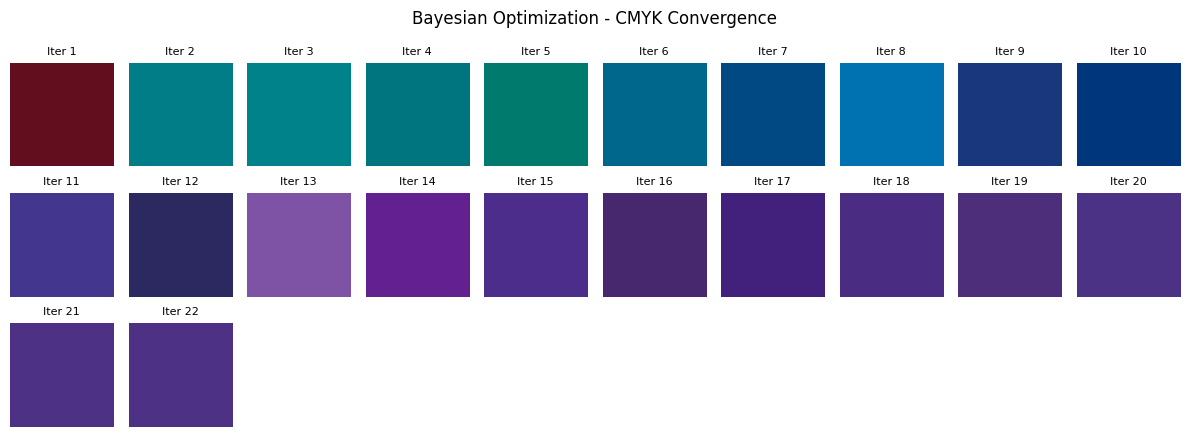

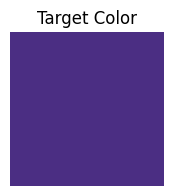

In [326]:
def CMYK_to_RGB(cmyk):
    C, M, Y, K = cmyk
    R = (1 - C) * (1 - K)
    G = (1 - M) * (1 - K)
    B = (1 - Y) * (1 - K)
    return np.array([R, G, B])

def visualize_iterations(train_x, target_rgb, colors_per_row=10):
    num_samples = train_x.shape[0]
    rgb_colors = np.array([CMYK_to_RGB(cmyk) for cmyk in train_x.numpy()])
    
    # determine grid layout
    n_rows = (num_samples + colors_per_row - 1) // colors_per_row  # Round up
    
    fig, axes = plt.subplots(n_rows, colors_per_row, figsize=(12, n_rows * 1.5))
    axes = axes.flatten()  # flatten for easier iteration

    for i in range(num_samples):
        ax = axes[i]
        ax.imshow([[rgb_colors[i]]], extent=[0, 1, 0, 1])
        ax.axis("off")
        ax.set_title(f"Iter {i+1}", fontsize=8)

    # hide unused subplots
    for j in range(num_samples, len(axes)):
        axes[j].axis("off")

    plt.suptitle("Bayesian Optimization - CMYK Convergence", fontsize=12)
    plt.tight_layout()
    plt.show()
    
    # show target color for reference
    plt.figure(figsize=(2, 2))
    plt.imshow([[target_rgb]], extent=[0, 1, 0, 1])
    plt.axis("off")
    plt.title("Target Color", fontsize=12)
    plt.show()

visualize_iterations(train_x, target_rgb, colors_per_row=10)